In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/full_datasets/aifs_single_hamburg_t2m_precip.csv",
                 parse_dates=["init_time", "valid_time"]
)

df.head()

,init_time,lead_time_h,valid_time,temperature_2m,precipitation_surface,latitude,longitude
0,2024-04-01,0.0,2024-04-01 00:00:00,6.78125,NaN,53.75,10.0
1,2024-04-01,6.0,2024-04-01 06:00:00,6.09375,0.000003,53.75,10.0
2,2024-04-01,12.0,2024-04-01 12:00:00,8.62500,0.000216,53.75,10.0
3,2024-04-01,18.0,2024-04-01 18:00:00,8.43750,0.000387,53.75,10.0
4,2024-04-01,24.0,2024-04-02 00:00:00,8.06250,0.000106,53.75,10.0


In [3]:
print(f"Anzahl Datensätze: {len(df):,}")

print("Vorhersagen ab:",
      df["init_time"].min())

print("Vorhersagen bis:",
      df["init_time"].max())

Anzahl Datensätze: 58,621
Vorhersagen ab: 2024-04-01 00:00:00
Vorhersagen bis: 2026-11-17 00:00:00


In [ ]:
#Zeitraum der Vorhersagen

In [4]:
sorted(df["lead_time_h"].unique())

[np.float64(0.0),
 np.float64(6.0),
 np.float64(12.0),
 np.float64(18.0),
 np.float64(24.0),
 np.float64(30.0),
 np.float64(36.0),
 np.float64(42.0),
 np.float64(48.0),
 np.float64(54.0),
 np.float64(60.0),
 np.float64(66.0),
 np.float64(72.0),
 np.float64(78.0),
 np.float64(84.0),
 np.float64(90.0),
 np.float64(96.0),
 np.float64(102.0),
 np.float64(108.0),
 np.float64(114.0),
 np.float64(120.0),
 np.float64(126.0),
 np.float64(132.0),
 np.float64(138.0),
 np.float64(144.0),
 np.float64(150.0),
 np.float64(156.0),
 np.float64(162.0),
 np.float64(168.0),
 np.float64(174.0),
 np.float64(180.0),
 np.float64(186.0),
 np.float64(192.0),
 np.float64(198.0),
 np.float64(204.0),
 np.float64(210.0),
 np.float64(216.0),
 np.float64(222.0),
 np.float64(228.0),
 np.float64(234.0),
 np.float64(240.0),
 np.float64(246.0),
 np.float64(252.0),
 np.float64(258.0),
 np.float64(264.0),
 np.float64(270.0),
 np.float64(276.0),
 np.float64(282.0),
 np.float64(288.0),
 np.float64(294.0),
 np.float64(300.0),

In [5]:
print("Anzahl Lead Times:",
      df["lead_time_h"].nunique())

Anzahl Lead Times: 61


In [ ]:
#Haben alle Vorhersagen die gleiche Anzahl an Lead Times?

In [6]:
lead_counts = (
    df.groupby("init_time")
      .size()
)

In [7]:
lead_counts.describe()

count    961.0
mean      61.0
std        0.0
min       61.0
25%       61.0
50%       61.0
75%       61.0
max       61.0
dtype: float64

In [8]:
lead_counts[lead_counts != 61]

Series([], dtype: int64)

In [ ]:
#fehlende Werte

In [9]:
missing = df.isna().sum()

pd.DataFrame({
    "Missing": missing,
    "Percent": missing / len(df) * 100
})

,Missing,Percent
init_time,0,0.000000
lead_time_h,0,0.000000
valid_time,0,0.000000
temperature_2m,0,0.000000
precipitation_surface,961,1.639344
latitude,0,0.000000
longitude,0,0.000000


In [ ]:
#fehlende Vorhersagen

In [10]:
daily_forecasts = (
    df.groupby(df["init_time"].dt.date)
      .size()
)

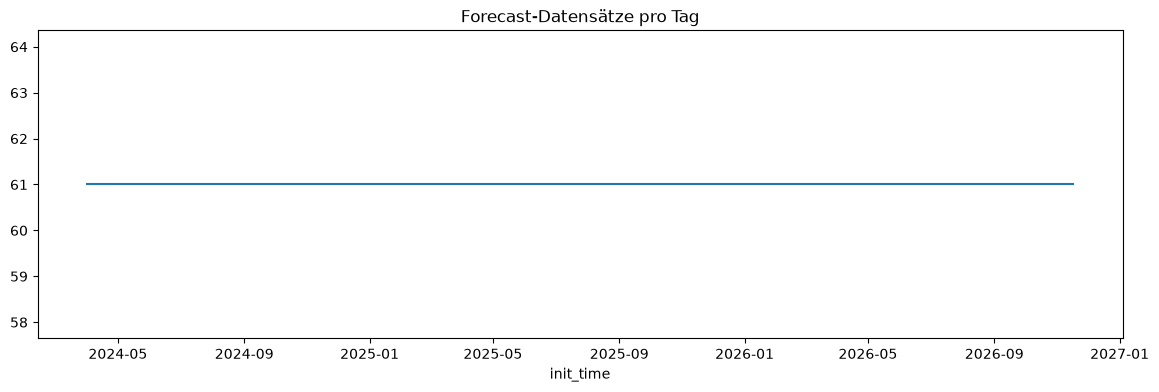

In [11]:
plt.figure(figsize=(14,4))

daily_forecasts.plot()

plt.title("Forecast-Datensätze pro Tag")
plt.show()

In [ ]:
#Temperaturverteilung

In [30]:
outliers = df[
    (df["temperature_2m"] < -50) |
    (df["temperature_2m"] > 50)
]

print(
    f"Verdächtige Datensätze: {len(outliers)}"
)

outliers.head()

Verdächtige Datensätze: 0


,init_time,lead_time_h,valid_time,temperature_2m,precipitation_surface,latitude,longitude,hour,month,forecast_date


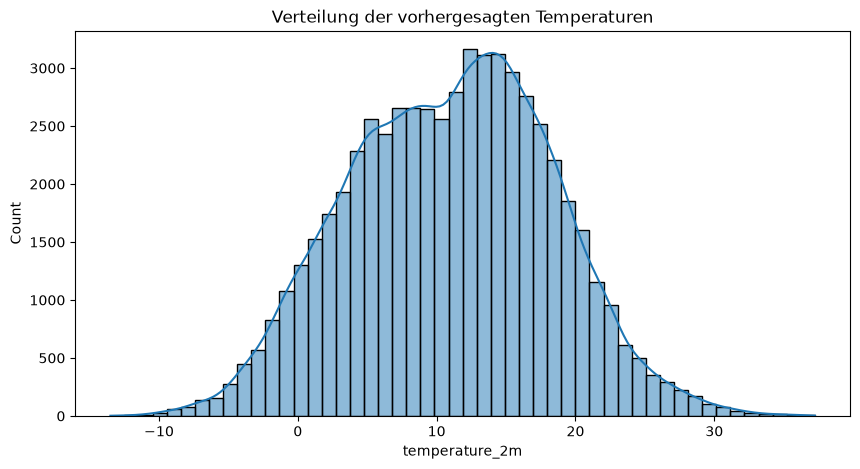

In [12]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["temperature_2m"],
    bins=50,
    kde=True
)

plt.title("Verteilung der vorhergesagten Temperaturen")
plt.show()

In [ ]:
#Temperaturverteilung nach Lead Time

In [13]:
mean_temp_by_lead = (
    df.groupby("lead_time_h")
      ["temperature_2m"]
      .mean()
)

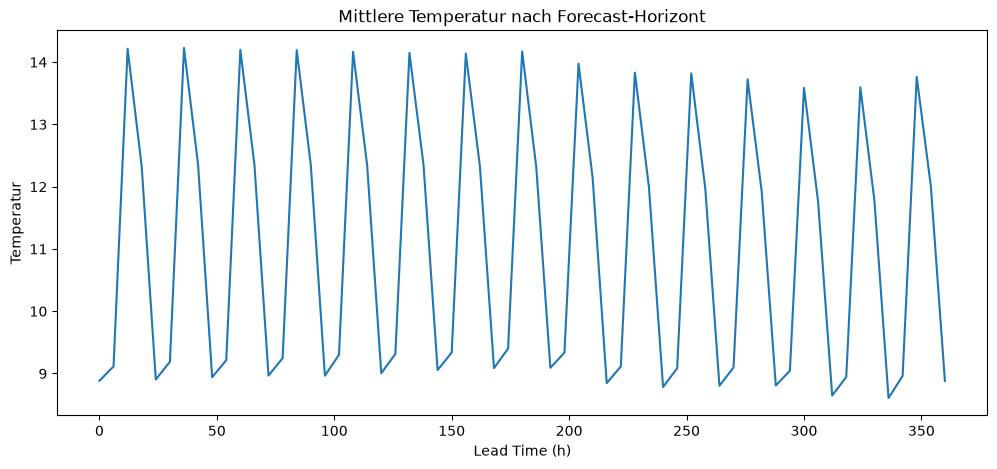

In [14]:
plt.figure(figsize=(12,5))

mean_temp_by_lead.plot()

plt.title("Mittlere Temperatur nach Forecast-Horizont")
plt.xlabel("Lead Time (h)")
plt.ylabel("Temperatur")
plt.show()

In [15]:
std_by_lead = (
    df.groupby("lead_time_h")
      ["temperature_2m"]
      .std()
)

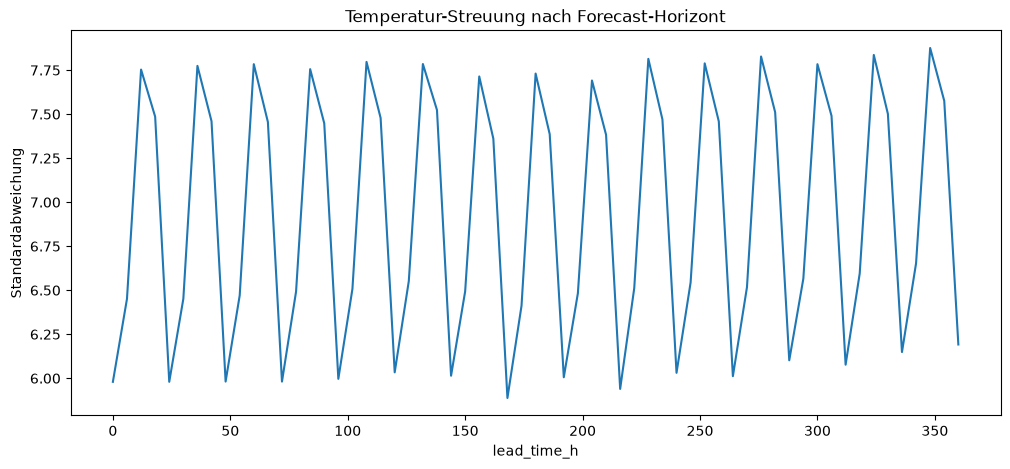

In [16]:
plt.figure(figsize=(12,5))

std_by_lead.plot()

plt.title("Temperatur-Streuung nach Forecast-Horizont")
plt.ylabel("Standardabweichung")
plt.show()

In [ ]:
#keine Ahnung, was das genau zeigt

In [ ]:
#Temperatur nach Tageszeit und Monat

In [17]:
df["hour"] = (
    df["valid_time"]
      .dt.hour
)

In [18]:
hourly = (
    df.groupby("hour")
      ["temperature_2m"]
      .mean()
)

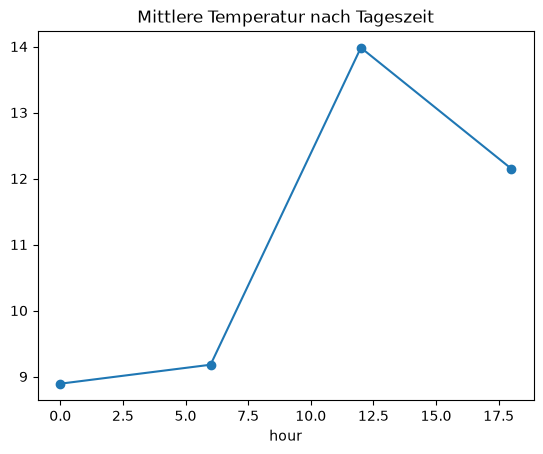

In [21]:
hourly.plot(marker="o")
plt.title("Mittlere Temperatur nach Tageszeit")
plt.show()

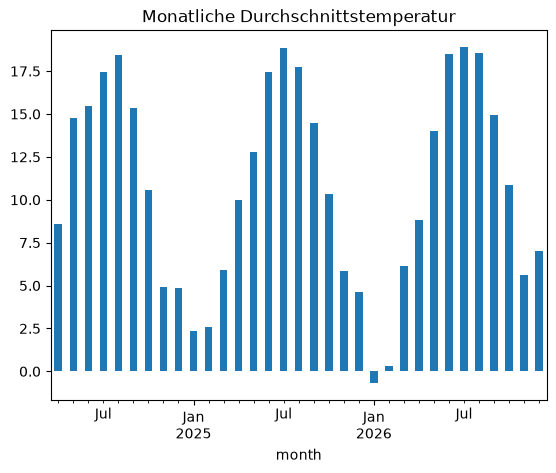

In [22]:
df["month"] = (
    df["valid_time"]
      .dt.to_period("M")
)

monthly = (
    df.groupby("month")
      ["temperature_2m"]
      .mean()
)

monthly.plot(kind="bar")
plt.title("Monatliche Durchschnittstemperatur")
plt.show()

<Axes: xlabel='hour', ylabel='lead_time_h'>

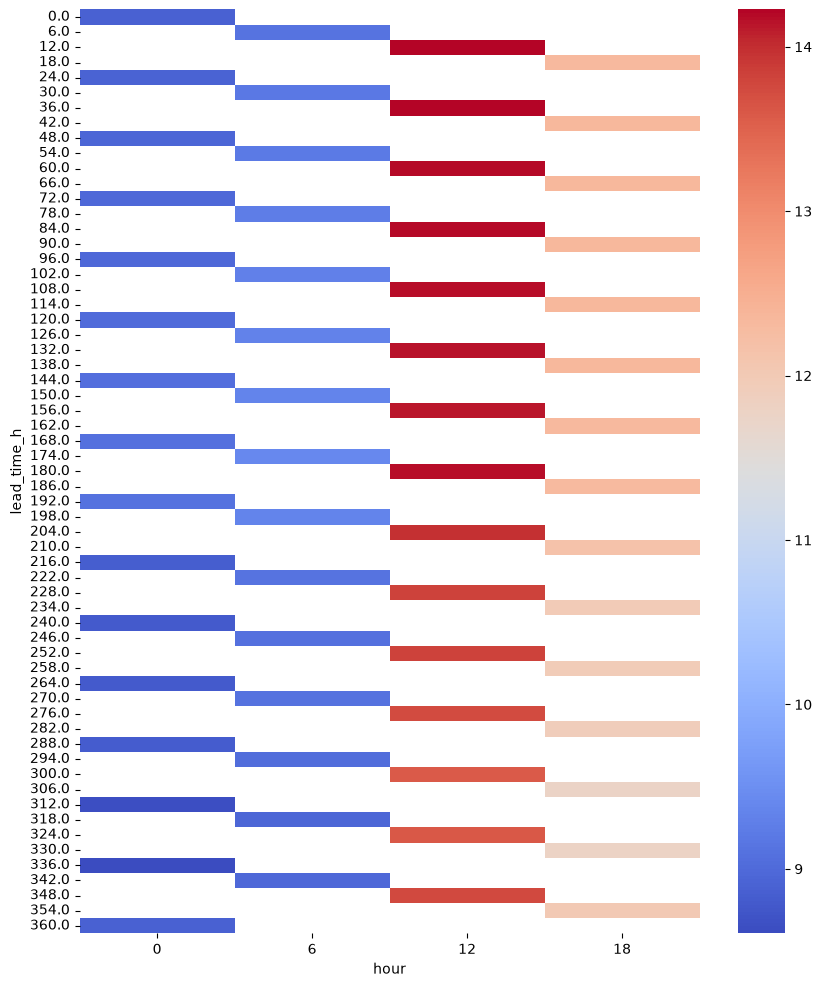

In [23]:
heatmap_data = (
    df.groupby(
        ["lead_time_h", "hour"]
    )["temperature_2m"]
    .mean()
    .unstack()
)

plt.figure(figsize=(10,12))

sns.heatmap(
    heatmap_data,
    cmap="coolwarm"
)

In [ ]:
#Niederschlagsvorhersage

In [24]:
dry_share = (
    (df["precipitation_surface"]
     .fillna(0) == 0)
    .mean()
)

print(f"{dry_share:.2%}")

29.87%


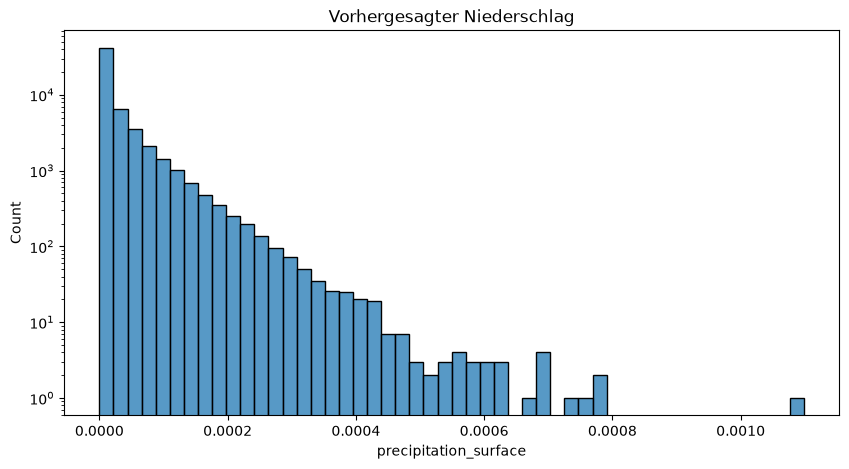

In [25]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["precipitation_surface"]
        .fillna(0),
    bins=50
)

plt.yscale("log")

plt.title("Vorhergesagter Niederschlag")
plt.show()

In [ ]:
#Vorhersagematrix

In [26]:
forecast_matrix = (
    df.pivot(
        index="init_time",
        columns="lead_time_h",
        values="temperature_2m"
    )
)

Text(158.33333333333331, 0.5, 'Forecast Run')

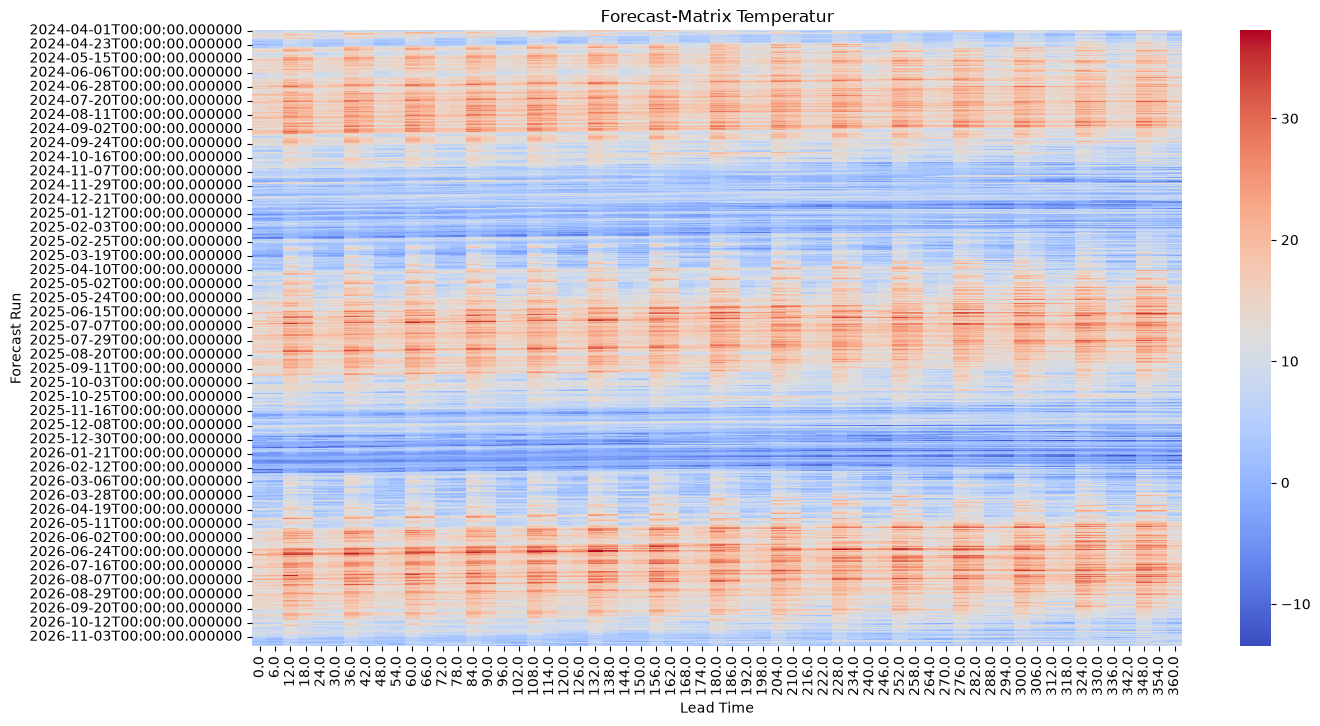

In [27]:
plt.figure(figsize=(15,8))

sns.heatmap(
    forecast_matrix,
    cmap="coolwarm"
)

plt.title("Forecast-Matrix Temperatur")
plt.xlabel("Lead Time")
plt.ylabel("Forecast Run")